In [1]:
%load_ext lab_black
%load_ext autoreload
%autoreload 2

In [2]:
import joblib
from feature_importance_utils import permute_importance_tau, plot_perm_importance
from compare_models import build_features
import pandas as pd

In [3]:
learner = joblib.load("../artifacts/learner.joblib")  # BlendedTauDF
train = pd.read_csv("../train_data.csv")
train_f = build_features(train)

In [4]:
feat_list = [
    "treatment_group",
    "brand_affinity_score",
    "web_activity_score",
    "price_sensitivity",
    "email_open_rate",
    "customer_tenure_days",
    "historical_lifetime_spend",
    "days_since_last_purchase",
    "log_hist_spend",
    "inv_days_since",
    "engagement_score",
    "engagement_mult",
    "affinity_x_recency",
    "log_tenure",
    "affinity_over_price",
    "price_sensitivity_sq",
    "day_of_week",
    "month",
    "quarter",
    "recency_bin",
]
feat_list = [f for f in feat_list if f in train_f.columns]

imp_blend_iroas = permute_importance_tau(
    df=train_f,
    predict_tau_df=learner.predict_tau_df,  # from your blended artifact
    features=feat_list,
    on="iROAS",
    n_repeats=5,
    random_state=42,
)

imp_blend_iroas.head(10)

,feature,importance,metric,on,n_repeats
0,days_since_last_purchase,91.80,MAE,iROAS,5
1,price_sensitivity,42.85,MAE,iROAS,5
2,brand_affinity_score,27.57,MAE,iROAS,5
3,historical_lifetime_spend,14.46,MAE,iROAS,5
4,email_open_rate,7.93,MAE,iROAS,5
5,web_activity_score,6.31,MAE,iROAS,5
6,customer_tenure_days,5.95,MAE,iROAS,5
7,treatment_group,0.00,MAE,iROAS,5
8,affinity_over_price,0.00,MAE,iROAS,5
9,quarter,0.00,MAE,iROAS,5


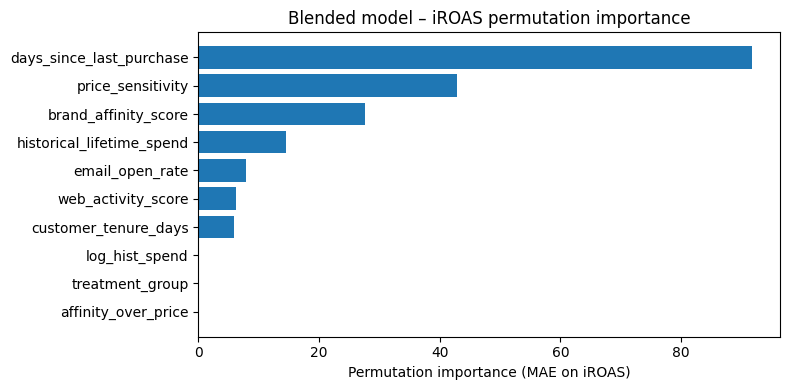

In [5]:
plot_perm_importance(
    imp_blend_iroas, top=10, title="Blended model – iROAS permutation importance"
)